# 📦 Quick Commerce Data Analytics & Visualization Project
## Operational Efficiency • Revenue Insights • Customer Behavior Analysis 
#####  Dataset: Excel 1M Sales Records
##### Records Analysed: 1,000,000
##### Tools: Python · Pandas · NumPy · Matplotlib · Seaborn
##### Total Visualisations: 22 charts across 14 sections

### 📦 SECTION 1 - IMPORTS & SETUP

In [65]:
 # Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries loaded!")


✅ Libraries loaded!


### 📥 SECTION 2 - LOAD DATA

In [67]:
# Load DataSet

df = pd.read_csv('../data/quick_commerce_data_raw.csv')
df_main = df.copy()

print("Shape:", df_main.shape)
print("\nColumns:", df_main.columns.tolist())
df_main.head()

Shape: (1000000, 13)

Columns: ['Order_ID', 'Company', 'City', 'Customer_Age', 'Order_Value', 'Delivery_Time_Min', 'Distance_Km', 'Items_Count', 'Product_Category', 'Payment_Method', 'Customer_Rating', 'Discount_Applied', 'Delivery_Partner_Rating']


,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.33750,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2
1,1000002,Flipkart Minutes,Amritsar,56,1007.30000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,NaN,Personal Care,Cash on Delivery,3.3,0,3.8
3,1000004,Swiggy Instamart,Delhi,23,1179.05925,5.864,6.44,2.0,Dairy,Credit Card,5.0,1,5.0
4,1000005,Dunzo,Mumbai,44,586.02550,12.470,2.45,13.0,Household,Wallet,3.7,0,4.8


### 🧹 🛠️ SECTION 3 - DATA CLEANING &  FIXING COLUMNS

In [68]:
  # Fix column names
df_main.columns = df_main.columns.str.lower().str.replace(' ', '_')

# Check missing values
print("Missing values:\n", df_main.isnull().sum())

# Remove duplicates
df_main.drop_duplicates(inplace=True)
print("\n✅ Shape after cleaning:", df_main.shape)

Missing values:
 order_id                        0
company                         0
city                        52000
customer_age                    0
order_value                     0
delivery_time_min               0
distance_km                     0
items_count                 35000
product_category                0
payment_method                  0
customer_rating             47000
discount_applied                0
delivery_partner_rating    104137
dtype: int64

✅ Shape after cleaning: (1000000, 13)


In [69]:
# Handle Missing Values (updated)

df_main['city'] = df_main['city'].fillna(df_main['city'].mode()[0])
df_main['items_count'] = df_main['items_count'].fillna(df_main['items_count'].median())
df_main['customer_rating'] = df_main['customer_rating'].fillna(df_main['customer_rating'].median())
df_main['delivery_partner_rating'] = df_main['delivery_partner_rating'].fillna(df_main['delivery_partner_rating'].median())

# Verify
print("Missing values after fix:\n", df_main.isnull().sum())
print("\n✅ Done!")

Missing values after fix:
 order_id                   0
company                    0
city                       0
customer_age               0
order_value                0
delivery_time_min          0
distance_km                0
items_count                0
product_category           0
payment_method             0
customer_rating            0
discount_applied           0
delivery_partner_rating    0
dtype: int64

✅ Done!


In [70]:
# Delivery Delay — derived from real delivery time
df_main['delivery_delay'] = df_main['delivery_time_min'].apply(
    lambda x: 'Yes' if x > 30 else 'No'
)

# Refund Requested — derived from real customer rating
df_main['refund_requested'] = df_main['customer_rating'].apply(
    lambda x: 'Yes' if x <= 2 else 'No'
)

In [71]:
# Add Derived Columns
df_main['delivery_delay'] = df_main['delivery_time_min'].apply(
    lambda x: 'Yes' if x > 30 else 'No'
)

df_main['refund_requested'] = df_main['customer_rating'].apply(
    lambda x: 'Yes' if x <= 2 else 'No'
)

print("✅ Done! Final shape:", df_main.shape)
print("✅ Columns:", df_main.columns.tolist())

✅ Done! Final shape: (1000000, 15)
✅ Columns: ['order_id', 'company', 'city', 'customer_age', 'order_value', 'delivery_time_min', 'distance_km', 'items_count', 'product_category', 'payment_method', 'customer_rating', 'discount_applied', 'delivery_partner_rating', 'delivery_delay', 'refund_requested']


In [72]:
#  Save Cleaned File
df_main.to_csv('../data/quick_commerce_clean.csv', index=False)
print("✅ Saved!")

✅ Saved!


### 🔍 SECTION 4 - DESCRIPTIVE STATISTICS & STRUCTURE 

In [73]:
# data structure
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Order_ID                 1000000 non-null  int64  
 1   Company                  1000000 non-null  str    
 2   City                     948000 non-null   str    
 3   Customer_Age             1000000 non-null  int64  
 4   Order_Value              1000000 non-null  float64
 5   Delivery_Time_Min        1000000 non-null  float64
 6   Distance_Km              1000000 non-null  float64
 7   Items_Count              965000 non-null   float64
 8   Product_Category         1000000 non-null  str    
 9   Payment_Method           1000000 non-null  str    
 10  Customer_Rating          953000 non-null   float64
 11  Discount_Applied         1000000 non-null  int64  
 12  Delivery_Partner_Rating  895863 non-null   float64
dtypes: float64(6), int64(3), str(4)
memory usage: 99.2 MB


In [74]:
#summary statistics
df.describe()

,Order_ID,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,965000.000000,953000.000000,1000000.000000,895863.000000
mean,1.500000e+06,38.470387,571.643584,16.452412,7.750231,9.998317,3.042072,0.400883,3.749257
std,2.886753e+05,12.118520,382.784520,6.257172,4.186665,5.478725,1.186872,0.490078,0.722121
min,1.000001e+06,18.000000,50.000000,5.000000,0.500000,1.000000,1.000000,0.000000,2.500000
25%,1.250001e+06,28.000000,287.840150,12.368000,4.130000,5.000000,2.000000,0.000000,3.100000
50%,1.500000e+06,38.000000,531.324600,16.342000,7.740000,10.000000,3.000000,0.000000,3.700000
75%,1.750000e+06,49.000000,796.182500,20.196000,11.380000,15.000000,4.000000,1.000000,4.400000
max,2.000000e+06,59.000000,13877.325000,40.000000,15.000000,19.000000,5.000000,1.000000,5.000000


In [75]:
# Q1 — Which city has most orders?
print(df_main['city'].value_counts().head(10))

city
Hyderabad    131481
Delhi         79183
Kolkata       79174
Mumbai        79078
Amritsar      79074
Gurgaon       79004
Bengluru      78973
Haridwar      78958
Jaipur        78901
Noida         78869
Name: count, dtype: int64


In [17]:
# Q2 — Which company has most orders?
print(df_main['company'].value_counts())

company
Flipkart Minutes    125542
Blinkit             125464
Swiggy Instamart    125119
Zepto               125063
Dunzo               124900
Jio Mart            124783
Amazon Now          124658
Big Basket          124471
Name: count, dtype: int64


In [18]:
# Q3 — Most popular product category?
print(df_main['product_category'].value_counts())

product_category
Dairy                  143772
Groceries              143202
Household              142855
Snacks                 142798
Personal Care          142725
Beverages              142610
Fruits & Vegetables    142038
Name: count, dtype: int64


In [19]:
# Q4 — Average delivery time per city?
print(df_main.groupby('city')['delivery_time_min'].mean().sort_values())

city
Delhi         7.139339
Noida        15.512747
Chennai      15.534581
Kolkata      15.534904
Hyderabad    15.539992
Gurgaon      15.553255
Pune         15.558817
Amritsar     15.568514
Bengluru     16.515318
Mumbai       17.511957
Jaipur       20.549048
Haridwar     27.541573
Name: delivery_time_min, dtype: float64


In [20]:
# Q5 — Delay rate?
print(df_main['delivery_delay'].value_counts())
print("\nDelay %:")
print(df_main['delivery_delay'].value_counts(normalize=True) * 100)

delivery_delay
No     974156
Yes     25844
Name: count, dtype: int64

Delay %:
delivery_delay
No     97.4156
Yes     2.5844
Name: proportion, dtype: float64


In [21]:
# Q6 — Most used payment method?
print(df_main['payment_method'].value_counts())

payment_method
Cash on Delivery    200739
Debit Card          200038
Credit Card         199884
UPI                 199882
Wallet              199457
Name: count, dtype: int64


In [22]:
# Q8 — Customer rating distribution?
print(df_main['customer_rating'].value_counts().sort_index())

customer_rating
1.0    38266
1.0      217
1.1      228
1.1    12878
1.2     1190
       ...  
4.8    14588
4.8     3309
4.9    15970
5.0      711
5.0    50132
Name: count, Length: 86, dtype: int64


In [23]:
# Fix customer rating
df_main['customer_rating'] = pd.to_numeric(
    df_main['customer_rating'], errors='coerce'
)
df_main['customer_rating'] = df_main['customer_rating'].round(1)

# Verify
print(df_main['customer_rating'].value_counts().sort_index())

customer_rating
1.0    38483
1.1    13106
1.2    15488
1.3    18189
1.4    19656
1.5    20281
1.6    21583
1.7    22673
1.8    23133
1.9    23328
2.0    23600
2.1    23963
2.2    23811
2.3    23940
2.4    23862
2.5    23531
2.6    23702
2.7    23756
2.8    23958
2.9    24178
3.0    70749
3.1    23934
3.2    23769
3.3    23777
3.4    23894
3.5    23748
3.6    23704
3.7    24170
3.8    23539
3.9    23361
4.0    23580
4.1    23647
4.2    23323
4.3    23219
4.4    21795
4.5    20482
4.6    20201
4.7    19756
4.8    18318
4.9    15970
5.0    50843
Name: count, dtype: int64


         order_value  delivery_time_min    distance_km    items_count  \
count  999888.000000      999888.000000  999888.000000  999888.000000   
mean      570.882018          16.452367       7.750291       9.998462   
std       375.411202           6.257159       4.186635       5.381980   
min        50.000000           5.000000       0.500000       1.000000   
25%       287.809200          12.368000       4.130000       5.000000   
50%       531.278250          16.342000       7.740000      10.000000   
75%       796.036325          20.196000      11.380000      15.000000   
max      4964.193500          40.000000      15.000000      19.000000   

       customer_rating  
count    999888.000000  
mean          3.040090  
std           1.158682  
min           1.000000  
25%           2.100000  
50%           3.000000  
75%           4.000000  
max           5.000000  


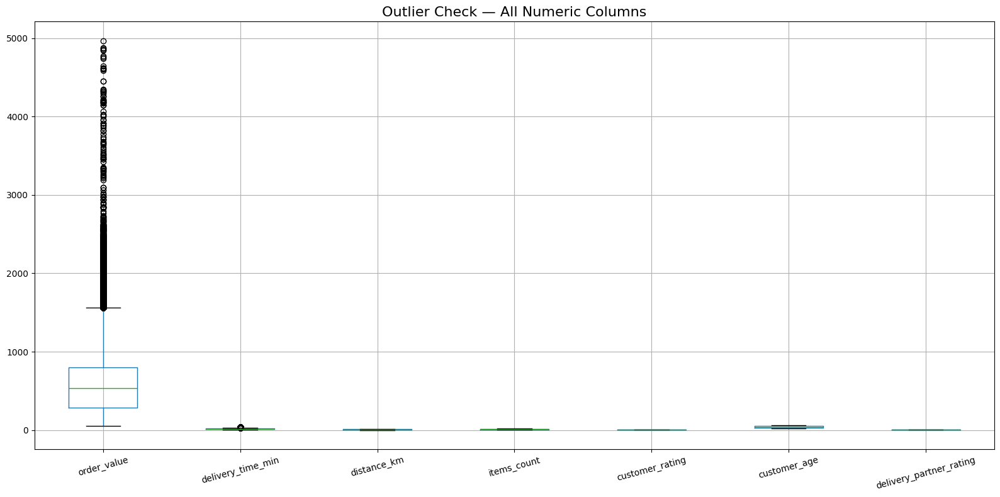

In [32]:
# Check for outliers
print(df_main[['order_value', 'delivery_time_min', 
               'distance_km', 'items_count', 
               'customer_rating']].describe())


# Single big boxplot for all numeric columns
plt.figure(figsize=(16, 8))

cols = ['order_value', 'delivery_time_min', 'distance_km', 
        'items_count', 'customer_rating', 'customer_age', 
        'delivery_partner_rating']

df_main[cols].boxplot(figsize=(16, 8))

plt.title('Outlier Check — All Numeric Columns', fontsize=16)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('../visuals/boxplot_outliers.png')
plt.show()

In [25]:
print(df_main[['customer_age', 'discount_applied', 
               'delivery_partner_rating']].describe())

         customer_age  discount_applied  delivery_partner_rating
count  1000000.000000    1000000.000000           1000000.000000
mean        38.470387          0.400883                 3.744127
std         12.118520          0.490078                 0.683653
min         18.000000          0.000000                 2.500000
25%         28.000000          0.000000                 3.200000
50%         38.000000          0.000000                 3.700000
75%         49.000000          1.000000                 4.300000
max         59.000000          1.000000                 5.000000


In [26]:
print("Orders above ₹5000:", (df_main['order_value'] > 5000).sum())
print("Orders above ₹10000:", (df_main['order_value'] > 10000).sum())

Orders above ₹5000: 112
Orders above ₹10000: 11


In [29]:
# Remove extreme outliers in order value
df_main = df_main[df_main['order_value'] <= 5000]

print("✅ Shape after removing outliers:", df_main.shape)

✅ Shape after removing outliers: (999888, 15)


In [33]:
df_main.to_csv('../data/quick_commerce_clean.csv', index=False)
print("✅ Clean file saved!")

✅ Clean file saved!


## Q1: Which city has the most orders?

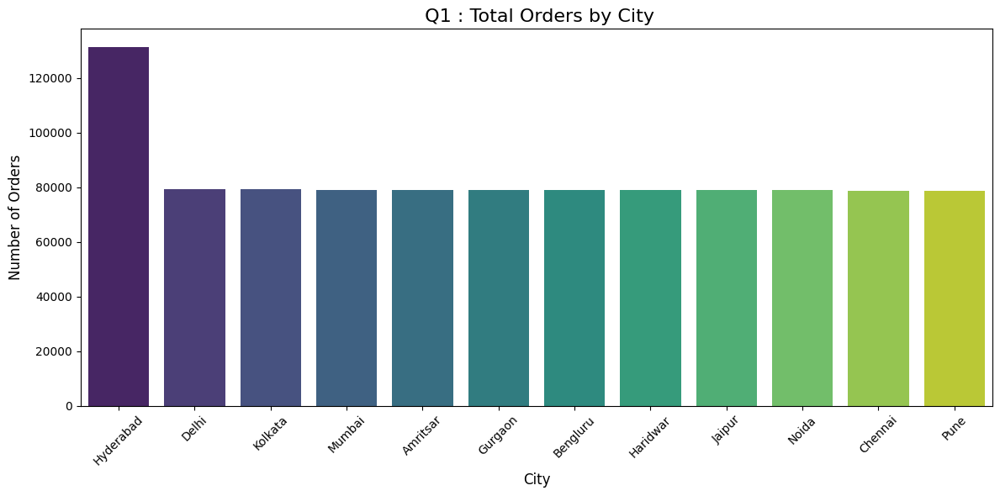

In [52]:
# Chart 1 — Orders by City
plt.figure(figsize=(12, 6))
city_counts = df_main['city'].value_counts()

sns.barplot(x=city_counts.index, y=city_counts.values, palette='viridis')

plt.title(' Q1 : Total Orders by City', fontsize=16)
plt.xlabel('City', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/01_orders_by_city.png')
plt.show()

## Q:2 Average Order Value by Platform

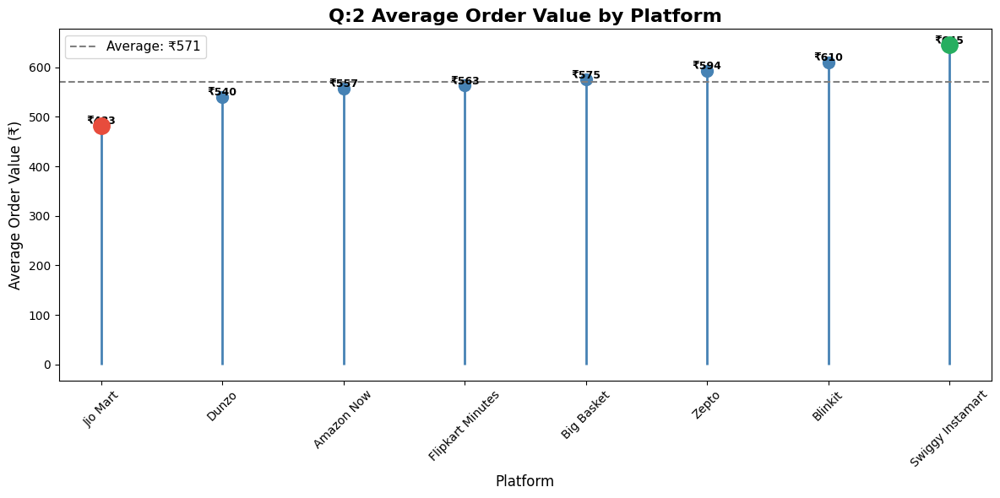

In [75]:


#  Highest Average Order Value by Platform
plt.figure(figsize=(12, 6))

company_value = df_main.groupby('company')['order_value'].mean().sort_values()

# Draw stems
plt.vlines(x=company_value.index, ymin=0, ymax=company_value.values,
           color='steelblue', linewidth=2)

# Draw circles
plt.plot(company_value.index, company_value.values,
         'o', color='steelblue', markersize=10)

# Highlight highest in green and lowest in red
plt.plot(company_value.index[-1], company_value.values[-1],
         'o', color='#27ae60', markersize=14, zorder=5)
plt.plot(company_value.index[0], company_value.values[0],
         'o', color='#e74c3c', markersize=14, zorder=5)

# Value labels
for x, y in zip(company_value.index, company_value.values):
    plt.text(x, y + 3, f'₹{y:.0f}', ha='center',
             fontsize=9, fontweight='bold')

# Average line
avg = company_value.mean()
plt.axhline(y=avg, color='gray', linestyle='--',
            linewidth=1.5, label=f'Average: ₹{avg:.0f}')
plt.legend(fontsize=11)

plt.title('Q:2 Average Order Value by Platform', fontsize=16, fontweight='bold')
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Average Order Value (₹)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/lollipop_order_value.png', dpi=150)
plt.show()

##  Q3: Which platform gets the most orders?

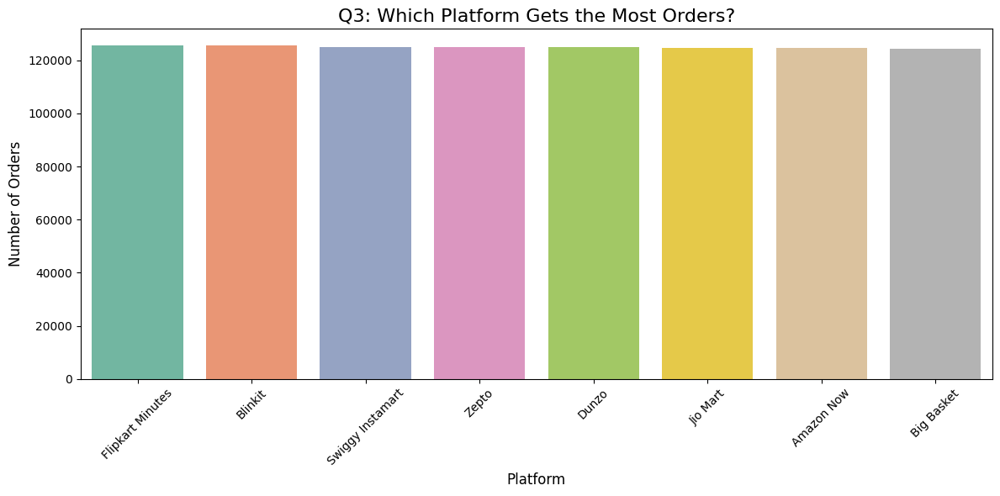

In [38]:
  # Chart 3 — Which platform gets the most orders?
plt.figure(figsize=(12, 6))
company_counts = df_main['company'].value_counts()
sns.barplot(x=company_counts.index, y=company_counts.values, palette='Set2')
plt.title('Q3: Which Platform Gets the Most Orders?', fontsize=16)
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/03_orders_by_platform.png')
plt.show()



## Q4: What are the most ordered categories?


Object `categories` not found.


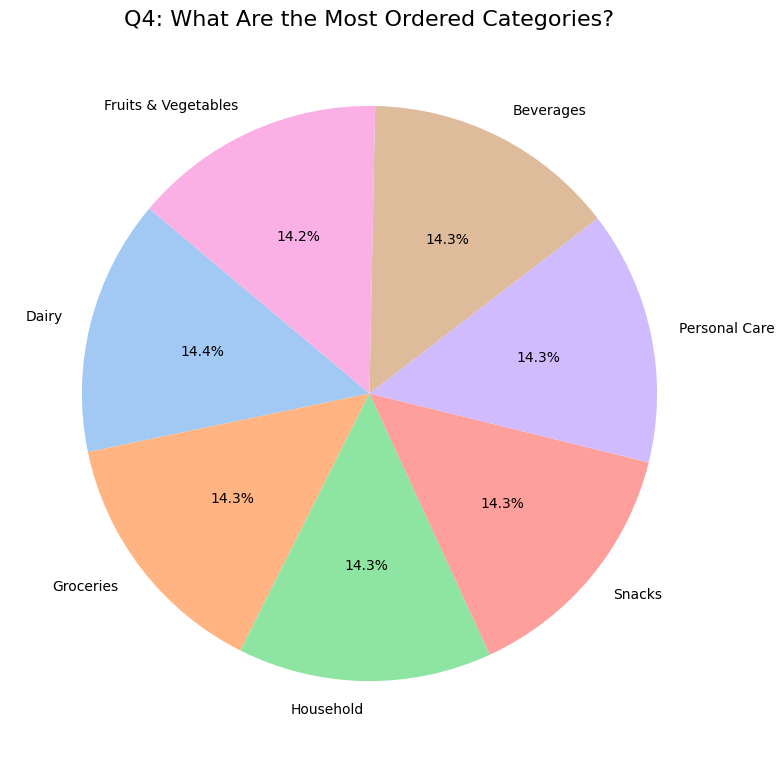

In [39]:
# What are the most ordered categories?
plt.figure(figsize=(8, 8))
category_counts = df_main['product_category'].value_counts()
plt.pie(category_counts.values, labels=category_counts.index,
        autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('pastel'))
plt.title('Q4: What Are the Most Ordered Categories?', fontsize=16)
plt.tight_layout()
plt.savefig('../visuals/04_product_categories.png')
plt.show()

## Q5: How Long Do Deliveries Usually Take?

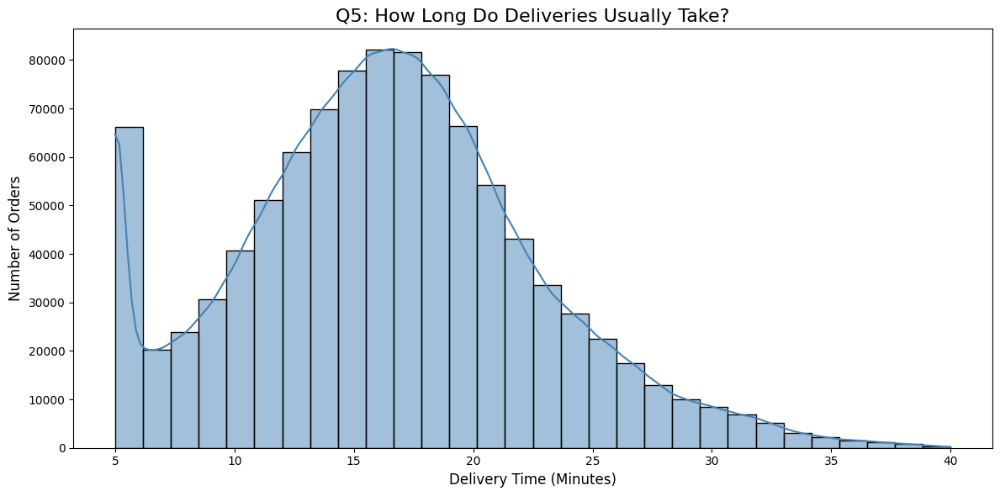

In [41]:
# How Long Do Deliveries Usually Take?
plt.figure(figsize=(12, 6))
sns.histplot(df_main['delivery_time_min'], bins=30, kde=True, color='steelblue')
plt.title('Q5: How Long Do Deliveries Usually Take?', fontsize=16)
plt.xlabel('Delivery Time (Minutes)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.tight_layout()
plt.savefig('../visuals/05_delivery_time_dist.png')
plt.show()

## Q6: Which platform has best delivery performance?

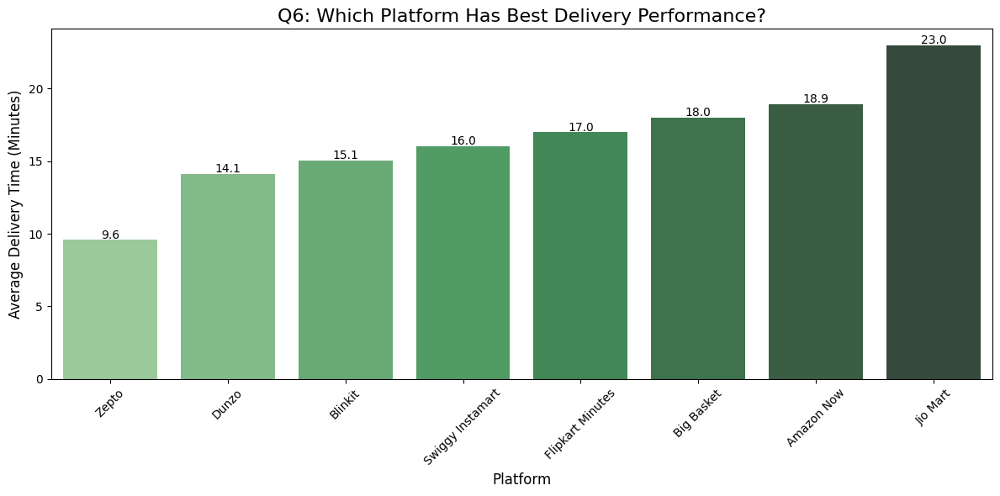

In [54]:
# Which platform has best delivery performance?

plt.figure(figsize=(12, 6))
company_delivery = df_main.groupby('company')['delivery_time_min'].mean().sort_values()
ax = sns.barplot(x=company_delivery.index, y=company_delivery.values, palette='Greens_d')
for i, v in enumerate(company_delivery.values):
    ax.text(i, v + 0.1, f'{v:.1f}', ha='center', fontsize=10)
plt.title('Q6: Which Platform Has Best Delivery Performance?', fontsize=16)
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Average Delivery Time (Minutes)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/09_delivery_by_platform.png')
plt.show()


## Q7: How does discount affect order value?


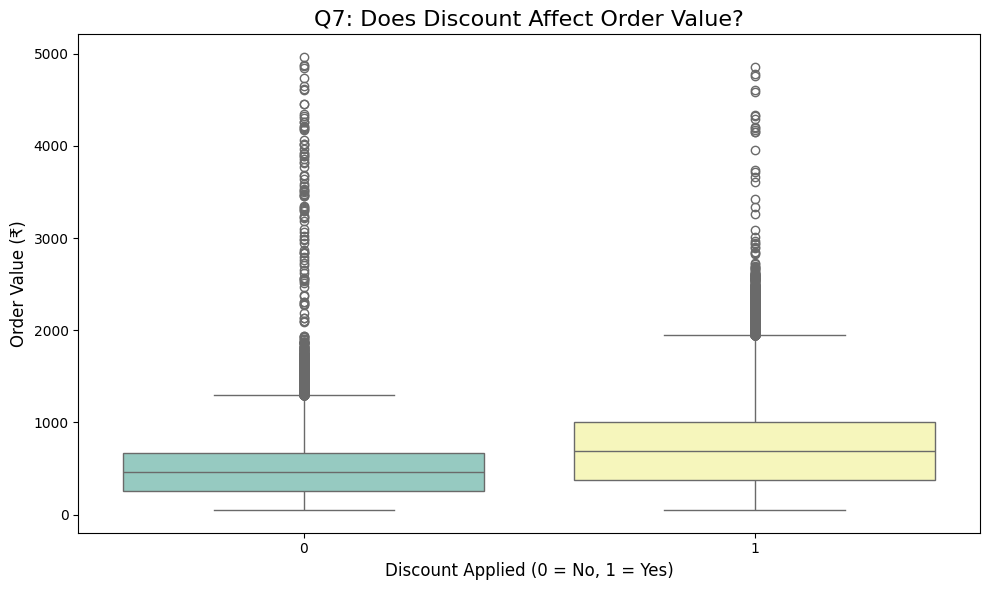

In [55]:
# How does discount affect order value?

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_main, x='discount_applied', y='order_value',
            palette='Set3')
plt.title('Q7: Does Discount Affect Order Value?', fontsize=16)
plt.xlabel('Discount Applied (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Order Value (₹)', fontsize=12)
plt.tight_layout()
plt.savefig('../visuals/10_discount_vs_order_value.png')
plt.show()

## Q8: Does Distance Affect Delivery Time?

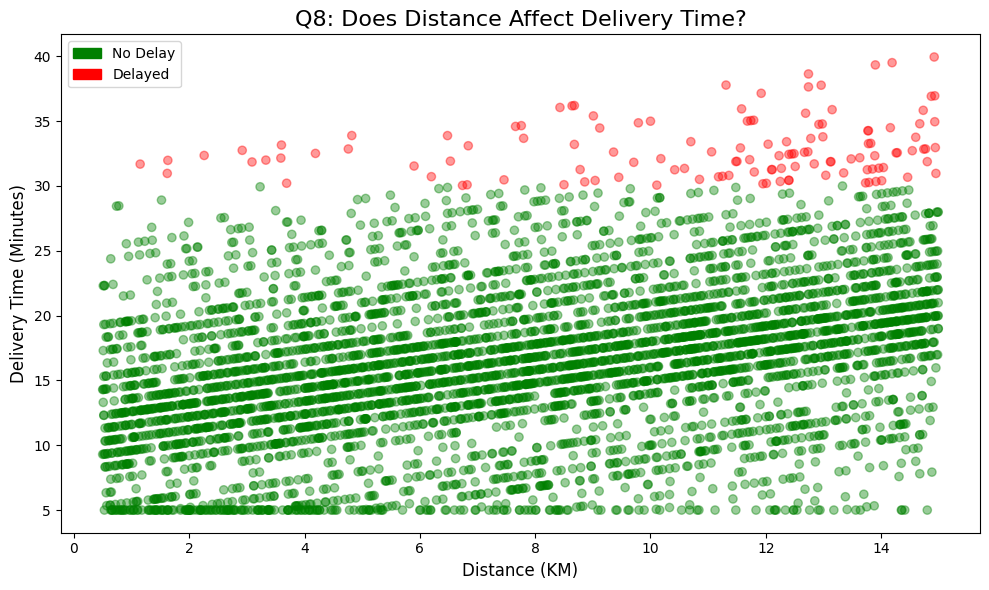

In [56]:
# Chart 8 — Does distance affect delivery time?
plt.figure(figsize=(10, 6))
sample = df_main.sample(5000, random_state=42)

# Color by delivery delay — green = no delay, red = delayed
colors = sample['delivery_delay'].map({'No': 'green', 'Yes': 'red'})

plt.scatter(sample['distance_km'], sample['delivery_time_min'],
            c=colors, alpha=0.4)

# Legend
from matplotlib.patches import Patch
legend = [Patch(color='green', label='No Delay'),
          Patch(color='red', label='Delayed')]
plt.legend(handles=legend)

plt.title('Q8: Does Distance Affect Delivery Time?', fontsize=16)
plt.xlabel('Distance (KM)', fontsize=12)
plt.ylabel('Delivery Time (Minutes)', fontsize=12)
plt.tight_layout()
plt.savefig('../visuals/08_distance_vs_delivery.png')
plt.show()

## Q9: Do Delayed Orders Get Lower Ratings

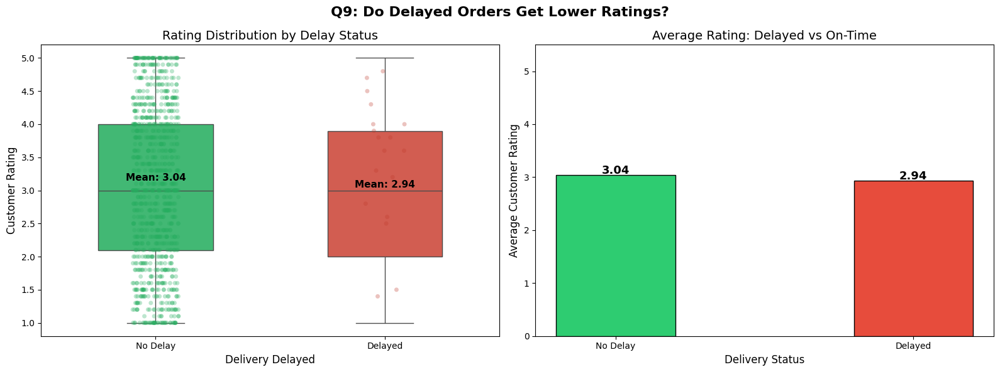

In [63]:

# Chart 6 — Do delayed orders get lower ratings?
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left — Boxplot with details
sns.boxplot(data=df_main, x='delivery_delay', y='customer_rating',
            palette={'No': '#2ecc71', 'Yes': '#e74c3c'},
            width=0.5, ax=axes[0])
sns.stripplot(data=df_main.sample(1000), x='delivery_delay', y='customer_rating',
              palette={'No': '#27ae60', 'Yes': '#c0392b'},
              alpha=0.3, jitter=True, ax=axes[0])
axes[0].set_title('Rating Distribution by Delay Status', fontsize=14)
axes[0].set_xlabel('Delivery Delayed', fontsize=12)
axes[0].set_ylabel('Customer Rating', fontsize=12)
axes[0].set_xticklabels(['No Delay', 'Delayed'])

# Add mean labels
for i, group in enumerate(['No', 'Yes']):
    mean_val = df_main[df_main['delivery_delay'] == group]['customer_rating'].mean()
    axes[0].text(i, mean_val + 0.1, f'Mean: {mean_val:.2f}',
                 ha='center', fontsize=11, fontweight='bold')

# Right — Average rating comparison bar chart
avg_ratings = df_main.groupby('delivery_delay')['customer_rating'].mean()
colors = ['#2ecc71', '#e74c3c']
bars = axes[1].bar(['No Delay', 'Delayed'], avg_ratings.values,
                    color=colors, width=0.4, edgecolor='black')
for bar, val in zip(bars, avg_ratings.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.02,
                 f'{val:.2f}', ha='center', fontsize=13, fontweight='bold')
axes[1].set_title('Average Rating: Delayed vs On-Time', fontsize=14)
axes[1].set_xlabel('Delivery Status', fontsize=12)
axes[1].set_ylabel('Average Customer Rating', fontsize=12)
axes[1].set_ylim(0, 5.5)

plt.suptitle('Q9: Do Delayed Orders Get Lower Ratings?', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../visuals/06_delay_vs_rating.png', dpi=150)
plt.show()

## Q10: Impact of Delivery Time on Delivery Partner Rating'

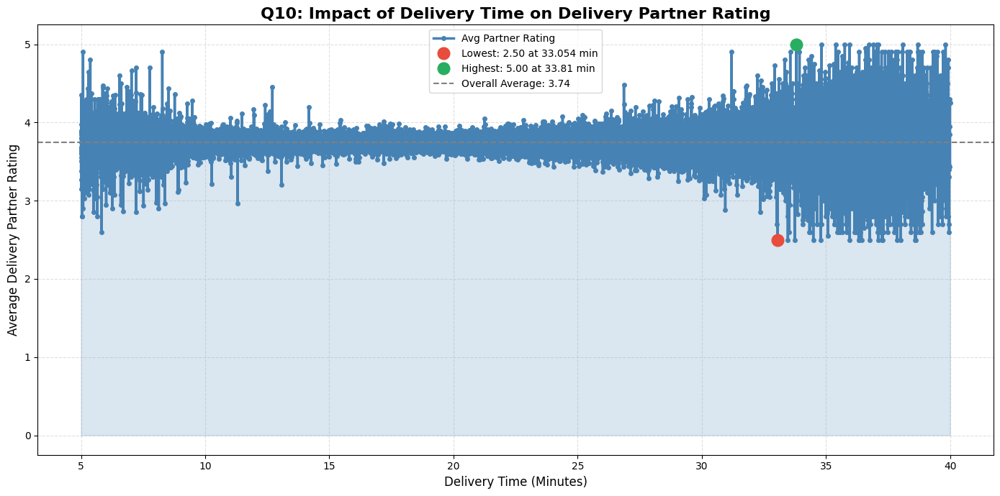

In [81]:
# Impact of Delivery Time on Delivery Partner Rating
plt.figure(figsize=(14, 7))

# Group by delivery time and get mean partner rating
delivery_rating = df_main.groupby('delivery_time_min')['delivery_partner_rating'].mean()

# Fill area under line
plt.fill_between(delivery_rating.index, delivery_rating.values,
                 alpha=0.2, color='steelblue')

# Main line
plt.plot(delivery_rating.index, delivery_rating.values,
         color='steelblue', linewidth=2.5, marker='o',
         markersize=4, label='Avg Partner Rating')

# Highlight min and max points
min_x = delivery_rating.idxmin()
max_x = delivery_rating.idxmax()

plt.plot(min_x, delivery_rating[min_x], 'o',
         color='#e74c3c', markersize=12, zorder=5,
         label=f'Lowest: {delivery_rating[min_x]:.2f} at {min_x} min')
plt.plot(max_x, delivery_rating[max_x], 'o',
         color='#27ae60', markersize=12, zorder=5,
         label=f'Highest: {delivery_rating[max_x]:.2f} at {max_x} min')

# Average line
avg = delivery_rating.mean()
plt.axhline(y=avg, color='gray', linestyle='--',
            linewidth=1.5, label=f'Overall Average: {avg:.2f}')

plt.title('Q10: Impact of Delivery Time on Delivery Partner Rating',
          fontsize=16, fontweight='bold')
plt.xlabel('Delivery Time (Minutes)', fontsize=12)
plt.ylabel('Average Delivery Partner Rating', fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis='both', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('../visuals/delivery_time_vs_partner_rating.png', dpi=150)
plt.show()

## Q11: Which Payment Method Do Customers Prefer?

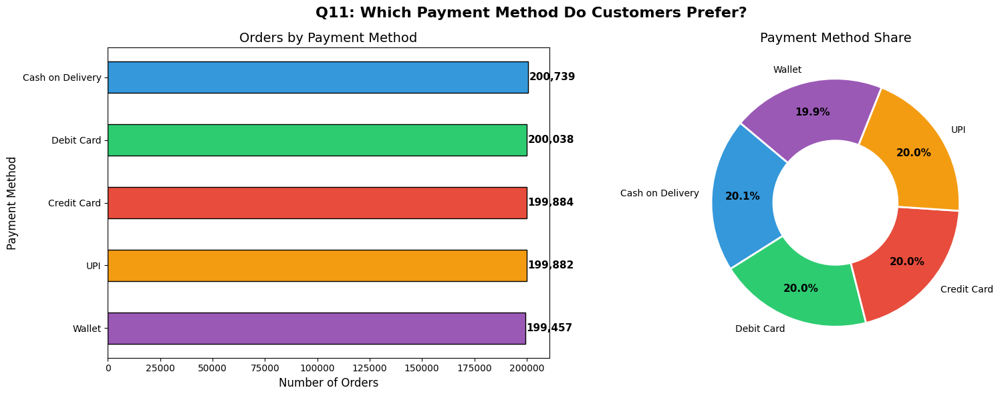

In [83]:
# Chart — Which payment method is preferred?
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

payment_counts = df_main['payment_method'].value_counts()
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

# Left — Horizontal bar chart with value labels
bars = axes[0].barh(payment_counts.index, payment_counts.values,
                     color=colors, edgecolor='black', height=0.5)
for bar, val in zip(bars, payment_counts.values):
    axes[0].text(val + 500, bar.get_y() + bar.get_height()/2,
                 f'{val:,}', va='center', fontsize=11, fontweight='bold')
axes[0].set_title('Orders by Payment Method', fontsize=14)
axes[0].set_xlabel('Number of Orders', fontsize=12)
axes[0].set_ylabel('Payment Method', fontsize=12)
axes[0].invert_yaxis()

# Right — Donut chart
wedges, texts, autotexts = axes[1].pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
    pctdistance=0.75
)
for text in autotexts:
    text.set_fontsize(11)
    text.set_fontweight('bold')
axes[1].set_title('Payment Method Share', fontsize=14)

plt.suptitle('Q11: Which Payment Method Do Customers Prefer?',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../visuals/05_payment_methods.png', dpi=150)
plt.show()

## Q12: Which Platform Dominates?

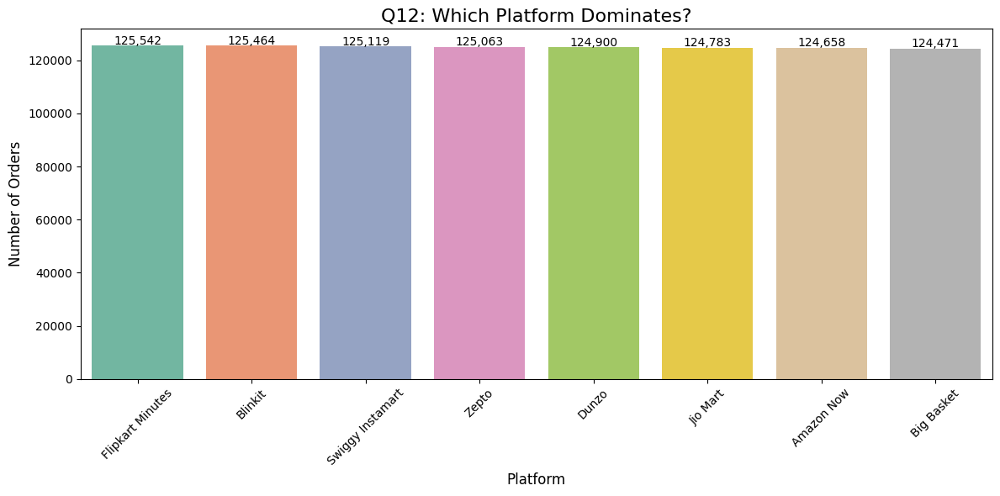

In [84]:


plt.figure(figsize=(12, 6))
company_counts = df_main['company'].value_counts()
ax = sns.barplot(x=company_counts.index, y=company_counts.values, palette='Set2')
for i, v in enumerate(company_counts.values):
    ax.text(i, v + 500, f'{v:,}', ha='center', fontsize=10)
plt.title('Q12: Which Platform Dominates?', fontsize=16)
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/02_orders_by_platform.png')
plt.show()


## Q13: Which Platform Performs Best?

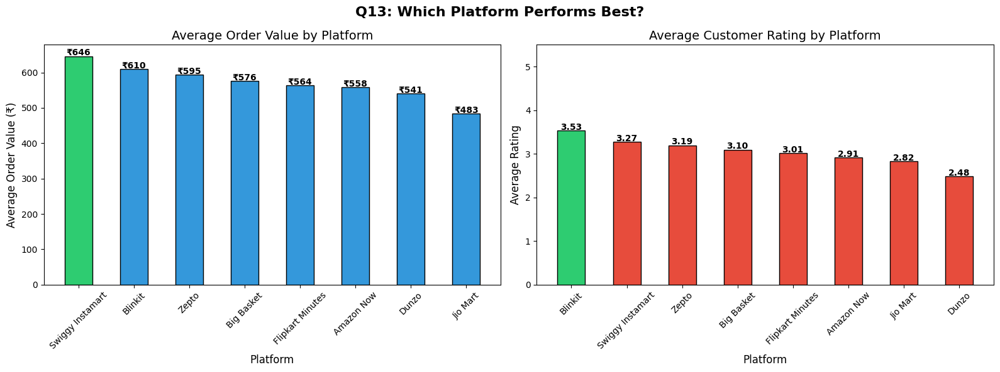

In [85]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

company_value = df_main.groupby('company')['order_value'].mean().sort_values(ascending=False)
company_rating = df_main.groupby('company')['customer_rating'].mean().sort_values(ascending=False)

# Left — Average order value
colors = ['#2ecc71' if v == company_value.max() else '#3498db' for v in company_value.values]
bars = axes[0].bar(company_value.index, company_value.values,
                    color=colors, edgecolor='black', width=0.5)
for bar, val in zip(bars, company_value.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 2,
                 f'₹{val:.0f}', ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Average Order Value by Platform', fontsize=14)
axes[0].set_xlabel('Platform', fontsize=12)
axes[0].set_ylabel('Average Order Value (₹)', fontsize=12)
axes[0].set_xticklabels(company_value.index, rotation=45)

# Right — Average customer rating
colors2 = ['#2ecc71' if v == company_rating.max() else '#e74c3c' for v in company_rating.values]
bars2 = axes[1].bar(company_rating.index, company_rating.values,
                     color=colors2, edgecolor='black', width=0.5)
for bar, val in zip(bars2, company_rating.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.02,
                 f'{val:.2f}', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Average Customer Rating by Platform', fontsize=14)
axes[1].set_xlabel('Platform', fontsize=12)
axes[1].set_ylabel('Average Rating', fontsize=12)
axes[1].set_ylim(0, 5.5)
axes[1].set_xticklabels(company_rating.index, rotation=45)

plt.suptitle('Q13: Which Platform Performs Best?', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../visuals/02_platform_performance.png', dpi=150)
plt.show()

## 'Q14:Total Revenue by Quick Commerce Platform

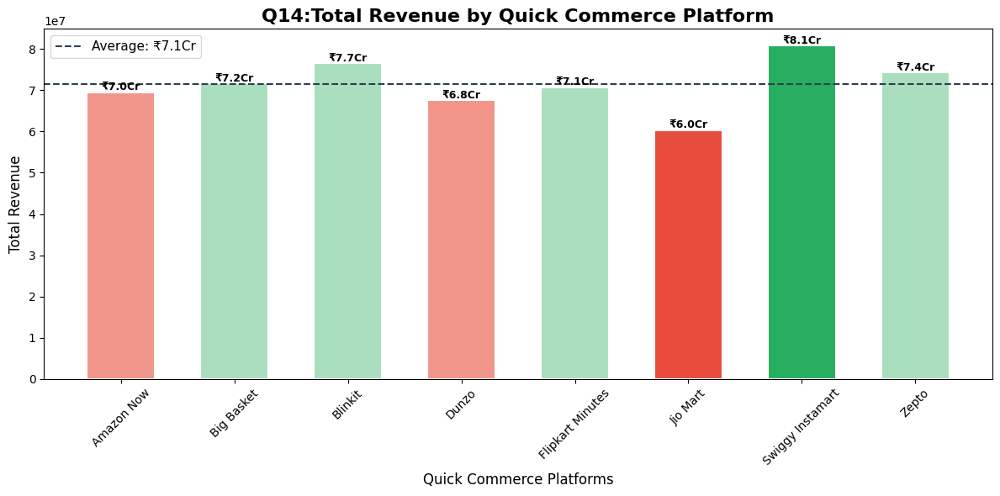

In [86]:
# Total Revenue by Platform
plt.figure(figsize=(12, 6))

company_revenue = df_main.groupby('company')['order_value'].sum().sort_index()

colors = []
for v in company_revenue.values:
    if v == company_revenue.max():
        colors.append('#27ae60')   # bright green — highest
    elif v == company_revenue.min():
        colors.append('#e74c3c')   # bright red — lowest
    else:
        # gradient shades between red and green
        normalized = (v - company_revenue.min()) / (company_revenue.max() - company_revenue.min())
        if normalized > 0.5:
            colors.append('#a9dfbf')  # light green
        else:
            colors.append('#f1948a')  # light red/pink

bars = plt.bar(company_revenue.index, company_revenue.values,
               color=colors, edgecolor='white', linewidth=1.5, width=0.6)

# Value labels on top
for bar, val in zip(bars, company_revenue.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 500000,
             f'₹{val/1e7:.1f}Cr', ha='center', fontsize=9, fontweight='bold')

# Average line
avg = company_revenue.mean()
plt.axhline(y=avg, color='#2c3e50', linestyle='--', linewidth=1.5, label=f'Average: ₹{avg/1e7:.1f}Cr')
plt.legend(fontsize=11)

plt.title('Q14:Total Revenue by Quick Commerce Platform', fontsize=16, fontweight='bold')
plt.xlabel('Quick Commerce Platforms', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../visuals/revenue_by_platform.png', dpi=150)
plt.show()

## Q15 : Customer Rating Distribution Across Platforms

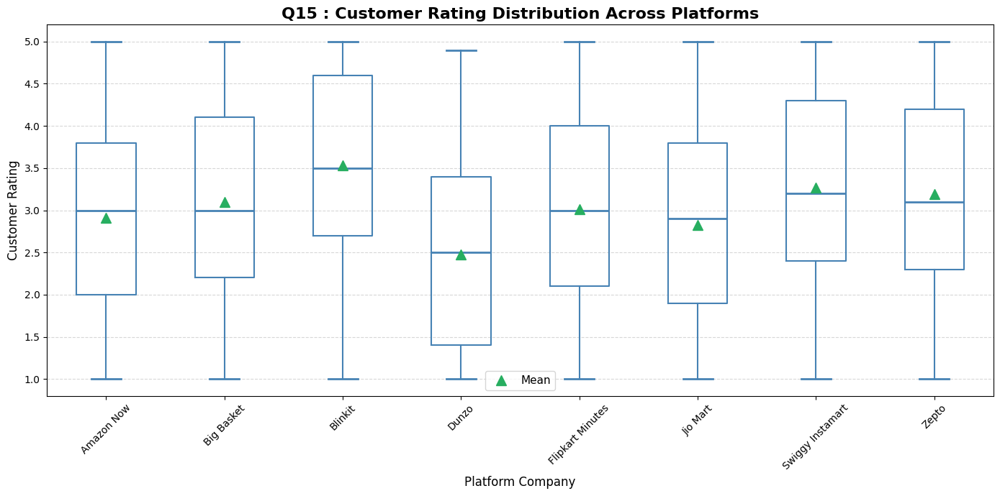

In [87]:
# Boxplot — Customer Rating Distribution Across Platforms
plt.figure(figsize=(14, 7))

companies = df_main['company'].unique()
data = [df_main[df_main['company'] == c]['customer_rating'].values for c in sorted(companies)]

bp = plt.boxplot(data, labels=sorted(companies),
                 patch_artist=False,
                 medianprops=dict(color='steelblue', linewidth=2),
                 whiskerprops=dict(color='steelblue', linewidth=1.5),
                 capprops=dict(color='steelblue', linewidth=2),
                 boxprops=dict(color='steelblue', linewidth=1.5))

# Add mean markers
for i, d in enumerate(data):
    mean_val = np.mean(d)
    plt.plot(i + 1, mean_val, '^', color='#27ae60',
             markersize=10, zorder=5, label='Mean' if i == 0 else '')

plt.title('Q15 : Customer Rating Distribution Across Platforms', fontsize=16, fontweight='bold')
plt.xlabel('Platform Company', fontsize=12)
plt.ylabel('Customer Rating', fontsize=12)
plt.xticks(rotation=45)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../visuals/boxplot_rating_by_platform.png', dpi=150)
plt.show()

## Q16:Customer Rating Distribution by Platform

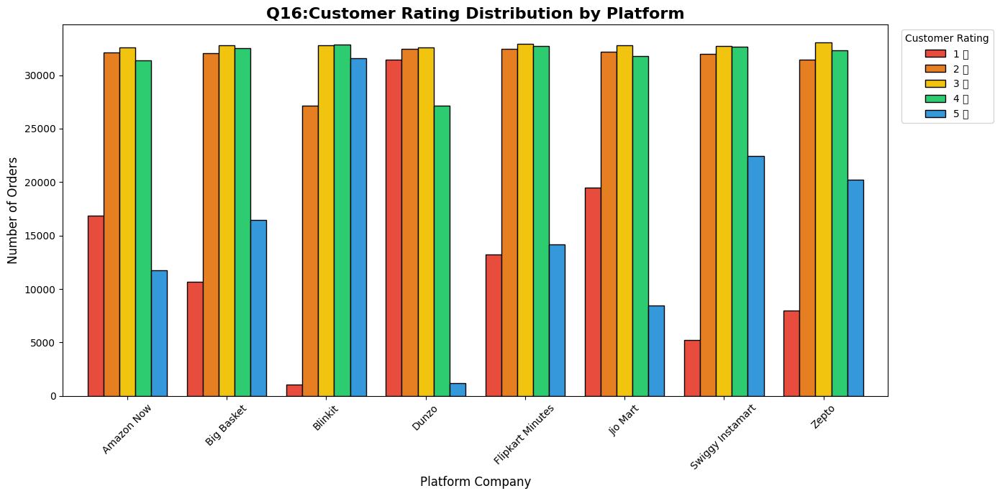

In [88]:
# Round ratings to whole numbers first
df_main['rating_rounded'] = df_main['customer_rating'].round(0).astype(int)

# Keep only 1-5
df_filtered = df_main[df_main['rating_rounded'].isin([1, 2, 3, 4, 5])]

# Grouped Bar Chart
rating_pivot = df_filtered.groupby(
    ['company', 'rating_rounded']
).size().unstack(fill_value=0)

rating_pivot.plot(kind='bar', figsize=(14, 7),
                  color=['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#3498db'],
                  edgecolor='black', width=0.8, ax=plt.gca())

plt.title('Q16:Customer Rating Distribution by Platform', fontsize=16, fontweight='bold')
plt.xlabel('Platform Company', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Customer Rating',
           labels=['1 ⭐', '2 ⭐', '3 ⭐', '4 ⭐', '5 ⭐'],
           bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../visuals/grouped_bar_rating_platform.png', dpi=150)
plt.show()

In [83]:
print(df.columns.tolist())

['Order_ID', 'Company', 'City', 'Customer_Age', 'Order_Value', 'Delivery_Time_Min', 'Distance_Km', 'Items_Count', 'Product_Category', 'Payment_Method', 'Customer_Rating', 'Discount_Applied', 'Delivery_Partner_Rating']


In [84]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['order_id', 'company', 'city', 'customer_age', 'order_value', 'delivery_time_min', 'distance_km', 'items_count', 'product_category', 'payment_method', 'customer_rating', 'discount_applied', 'delivery_partner_rating']


## Operational Efficiency of Quick Commerce Platforms

In [87]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# For Jupyter Notebook display
pio.renderers.default = 'notebook'

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Group company-wise statistics
company_stats = df.groupby('company').agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('delivery_time_min', 'mean'),
    total_revenue=('order_value', 'sum')
).reset_index()

# Create efficiency score
company_stats['efficiency_score'] = (
    company_stats['total_orders'] /
    company_stats['avg_delivery_time']
).round(2)

# Create interactive bubble chart
fig = px.scatter(
    company_stats,
    x='total_orders',
    y='avg_delivery_time',
    size='total_revenue',
    color='company',
    text='company',
    hover_name='company',
    hover_data={
        'total_orders': True,
        'avg_delivery_time': ':.2f',
        'total_revenue': ':.2f',
        'efficiency_score': True
    },
    size_max=60,
    template='plotly_dark',
    title='Operational Efficiency of Quick Commerce Platforms'
)

# Bubble styling
fig.update_traces(
    textposition='top center',
    marker=dict(
        line=dict(width=2, color='white'),
        opacity=0.85
    )
)

# Layout styling
fig.update_layout(
    xaxis_title='Total Orders (Higher is Better)',
    yaxis_title='Average Delivery Time in Minutes (Lower is Better)',
    title_x=0.5,
    height=650,
    width=1100,
    paper_bgcolor='black',
    plot_bgcolor='black',
    font=dict(
        family='Arial',
        size=13,
        color='white'
    ),
    legend_title='Company'
)

# Reverse Y-axis so efficient companies appear at TOP
fig.update_yaxes(autorange='reversed')

# Show chart
fig.show()

In [51]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, HTML

print('✅ All libraries loaded.')

✅ All libraries loaded.


In [98]:
df = pd.read_csv('quick_commerce_clean.csv')
print(df.columns.tolist())
print(df.shape)
df.head(2)

['order_id', 'company', 'city', 'customer_age', 'order_value', 'delivery_time_min', 'distance_km', 'items_count', 'product_category', 'payment_method', 'customer_rating', 'discount_applied', 'delivery_partner_rating', 'delivery_delay', 'refund_requested']
(999888, 15)


,order_id,company,city,customer_age,order_value,delivery_time_min,distance_km,items_count,product_category,payment_method,customer_rating,discount_applied,delivery_partner_rating,delivery_delay,refund_requested
0,1000001,Swiggy Instamart,Noida,46,702.3375,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2,No,No
1,1000002,Flipkart Minutes,Amritsar,56,1007.3000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2,No,No


In [57]:
df = pd.read_csv('quick_commerce_clean.csv')

# Basic cleaning — lowercase column names
df['order_value']              = pd.to_numeric(df['order_value'],              errors='coerce')
df['items_count']              = pd.to_numeric(df['items_count'],              errors='coerce')
df['discount_applied']         = pd.to_numeric(df['discount_applied'],         errors='coerce')
df['customer_rating']          = pd.to_numeric(df['customer_rating'],          errors='coerce')
df['delivery_time_min']        = pd.to_numeric(df['delivery_time_min'],        errors='coerce')
df['delivery_partner_rating']  = pd.to_numeric(df['delivery_partner_rating'],  errors='coerce')
df['distance_km']              = pd.to_numeric(df['distance_km'],              errors='coerce')
df.dropna(subset=['order_value'], inplace=True)

print(f'✅ Data loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

✅ Data loaded: 999,888 rows × 15 columns


,order_id,company,city,customer_age,order_value,delivery_time_min,distance_km,items_count,product_category,payment_method,customer_rating,discount_applied,delivery_partner_rating,delivery_delay,refund_requested
0,1000001,Swiggy Instamart,Noida,46,702.3375,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2,No,No
1,1000002,Flipkart Minutes,Amritsar,56,1007.3000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2,No,No
2,1000003,Flipkart Minutes,Mumbai,18,1211.6600,16.910,4.85,10.0,Personal Care,Cash on Delivery,3.3,0,3.8,No,No


In [58]:
BRAND_COLORS = [
    '#FF6B35', '#1E90FF', '#2ECC71', '#9B59B6',
    '#F39C12', '#E74C3C', '#1ABC9C', '#34495E'
]

KPI_STYLE = """
<style>
  .kpi-grid {
      display: grid;
      grid-template-columns: repeat(3, 1fr);
      gap: 14px;
      margin: 16px 0 24px 0;
      font-family: 'Segoe UI', sans-serif;
  }
  .kpi-card {
      background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%);
      border: 1px solid #0f3460;
      border-radius: 12px;
      padding: 18px 20px;
      text-align: center;
      box-shadow: 0 4px 15px rgba(0,0,0,0.3);
  }
  .kpi-label {
      font-size: 12px;
      text-transform: uppercase;
      letter-spacing: 1.2px;
      color: #8892b0;
      margin-bottom: 6px;
  }
  .kpi-value {
      font-size: 28px;
      font-weight: 700;
      color: #e6f1ff;
  }
  .kpi-icon  { font-size: 22px; margin-bottom: 4px; }
  .kpi-sub   { font-size: 11px; color: #64ffda; margin-top: 4px; }
  .dash-title {
      font-family: 'Segoe UI', sans-serif;
      font-size: 22px;
      font-weight: 700;
      color: #ccd6f6;
      border-left: 4px solid #FF6B35;
      padding-left: 12px;
      margin-bottom: 6px;
  }
</style>
"""

def fmt_inr(val):
    if val >= 1_000_000_000: return f'₹{val/1e9:.2f}B'
    if val >= 1_000_000:     return f'₹{val/1e6:.2f}M'
    if val >= 1_000:         return f'₹{val/1e3:.1f}K'
    return f'₹{val:.2f}'

def render_kpis(d):
    total_rev    = d['order_value'].sum()
    total_ord    = len(d)
    avg_order    = d['order_value'].mean()
    avg_deliv    = d['delivery_time_min'].mean()
    avg_rating   = d['customer_rating'].mean()
    avg_disc     = d['discount_applied'].mean()
    refund_rate  = (d['refund_requested'] == 'Yes').mean() * 100
    delay_rate   = (d['delivery_delay'] == 'Yes').mean() * 100

    cards = [
        ('💰', 'Total Revenue',        fmt_inr(total_rev),          ''),
        ('📦', 'Total Orders',         f'{total_ord:,}',             ''),
        ('🧾', 'Avg Order Value',      fmt_inr(avg_order),          'per order'),
        ('🚀', 'Avg Delivery Time',    f'{avg_deliv:.1f} min',      ''),
        ('⭐', 'Avg Customer Rating',  f'{avg_rating:.2f} / 5',     ''),
        ('🏷️', 'Avg Discount',         f'{avg_disc:.2f}',           'applied'),
        ('↩️', 'Refund Rate',           f'{refund_rate:.1f}%',       'of orders'),
        ('⏰', 'Delivery Delay Rate',  f'{delay_rate:.1f}%',        'of orders'),
    ]
    html = KPI_STYLE + '<div class="kpi-grid">'
    for icon, label, value, sub in cards:
        html += f"""
        <div class="kpi-card">
          <div class="kpi-icon">{icon}</div>
          <div class="kpi-label">{label}</div>
          <div class="kpi-value">{value}</div>
          <div class="kpi-sub">{sub}</div>
        </div>"""
    html += '</div>'
    return HTML(html)

CHART_LAYOUT = dict(
    paper_bgcolor='#0d1117',
    plot_bgcolor='#0d1117',
    font=dict(color='#ccd6f6', family='Segoe UI'),
    margin=dict(t=45, b=30, l=30, r=20),
    title_font=dict(size=14, color='#e6f1ff'),
)

print('✅ Helper functions ready.')

✅ Helper functions ready.


# INTERACTIVE DASHBOARD 

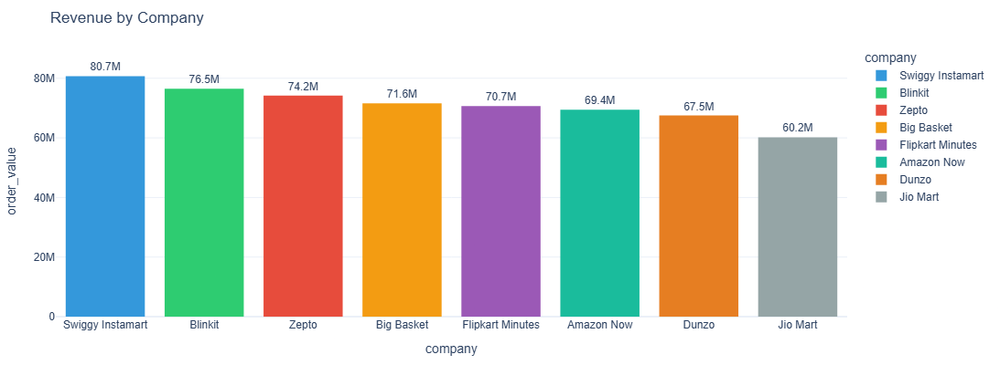

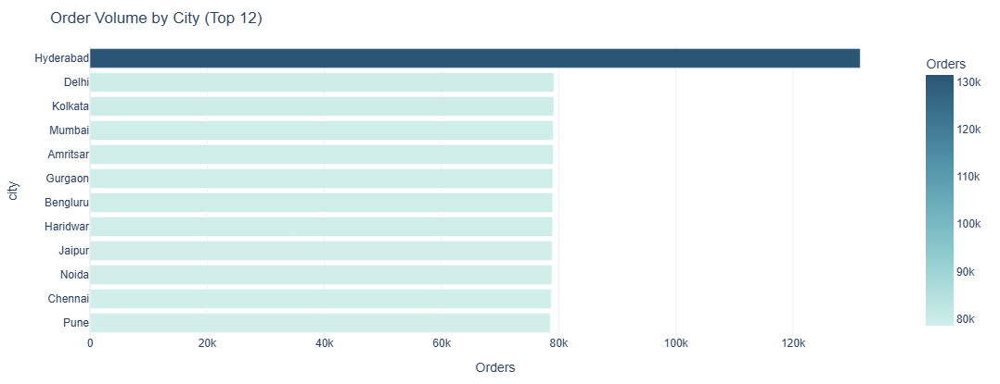

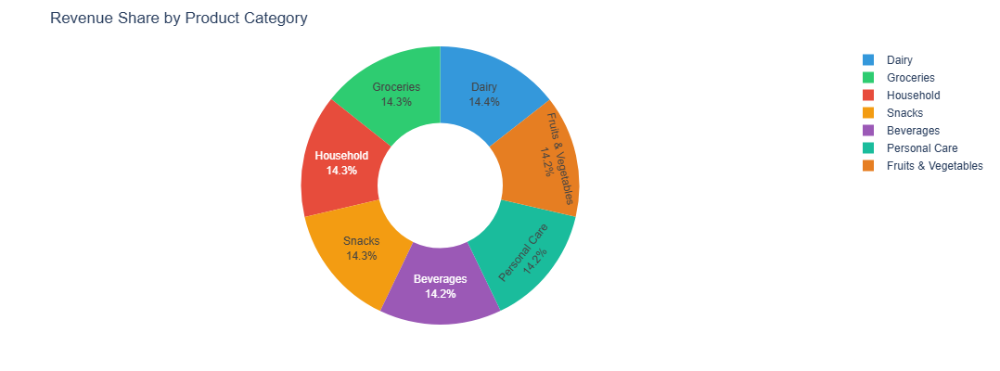

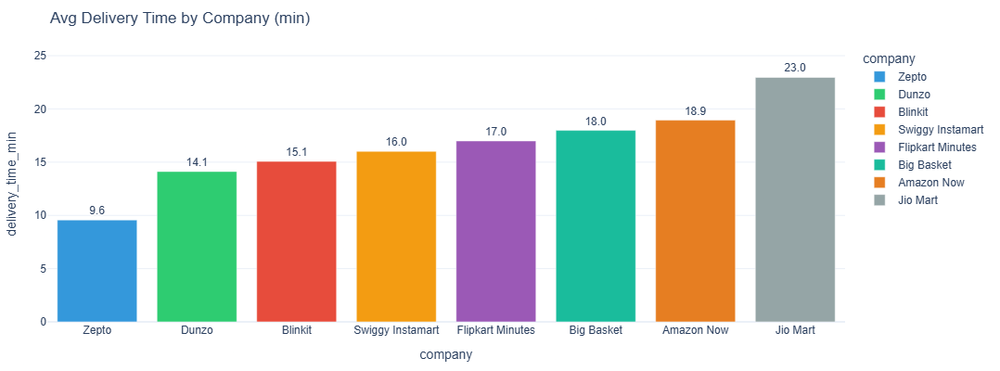

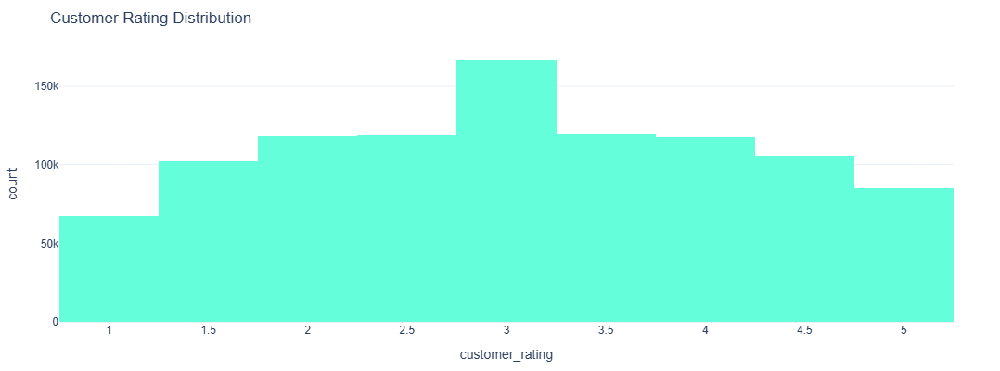

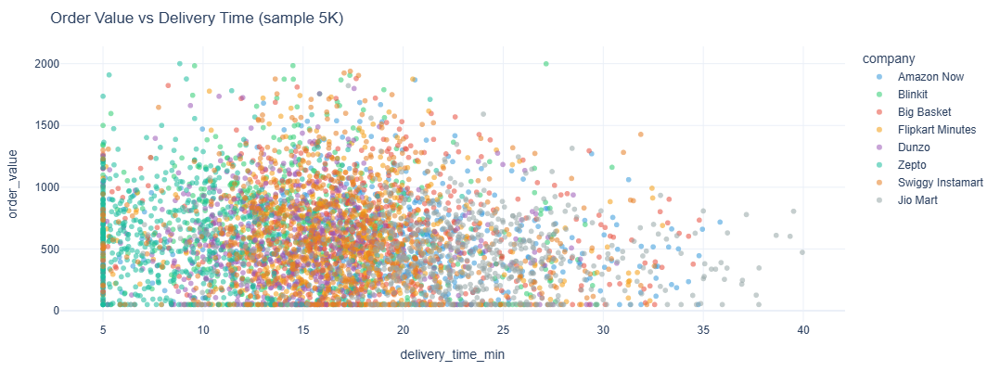

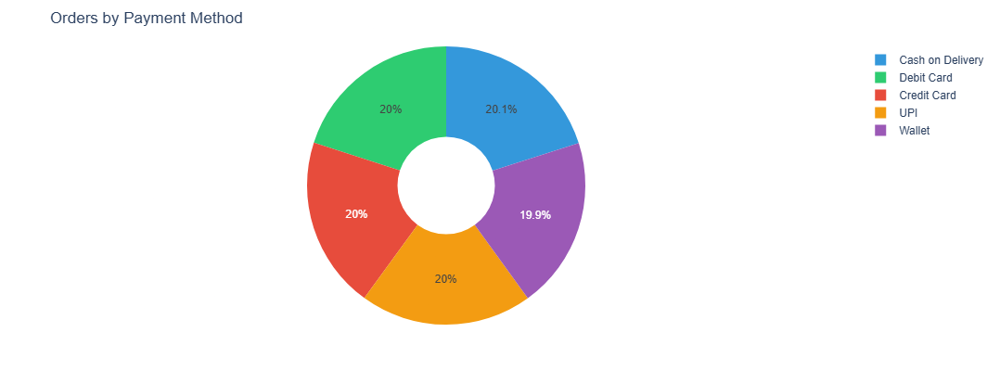

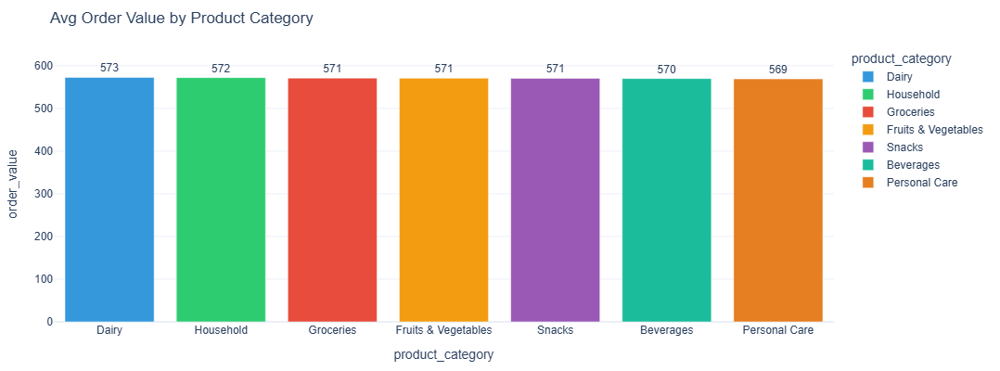

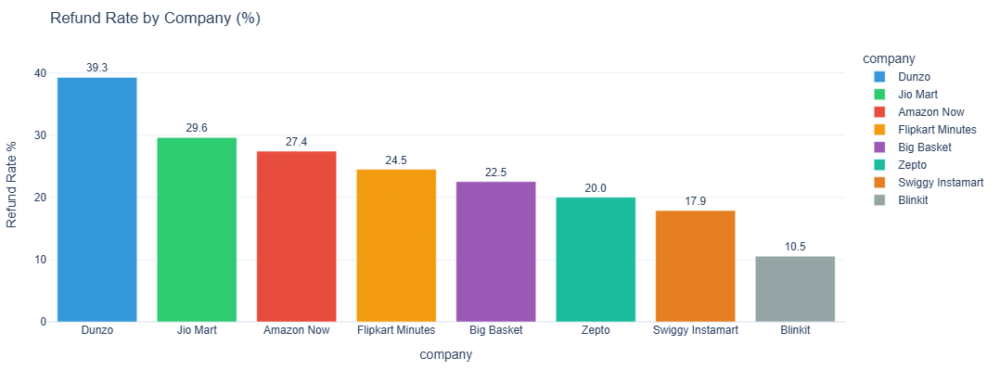

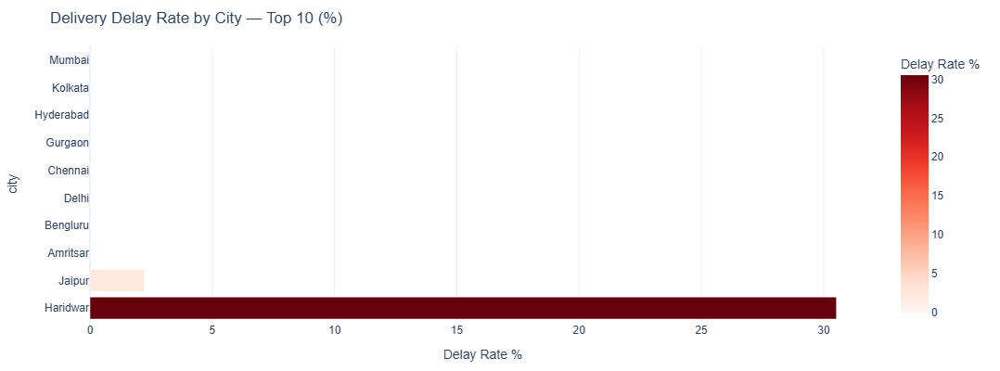

In [99]:
ALL = 'All'

# ── Widgets ──────────────────────────────────────────────────────────────────
company_opts  = [ALL] + sorted(df['company'].dropna().unique().tolist())
city_opts     = [ALL] + sorted(df['city'].dropna().unique().tolist())
category_opts = [ALL] + sorted(df['product_category'].dropna().unique().tolist())

style_dd  = {'description_width': '90px'}
layout_dd = widgets.Layout(width='220px')

w_company  = widgets.Dropdown(options=company_opts,  value=ALL,
                               description='🏢 Company',  style=style_dd, layout=layout_dd)
w_city     = widgets.Dropdown(options=city_opts,     value=ALL,
                               description='🏙️ City',      style=style_dd, layout=layout_dd)
w_category = widgets.Dropdown(options=category_opts, value=ALL,
                               description='🛍️ Category',  style=style_dd, layout=layout_dd)
w_reset    = widgets.Button(description='↺ Reset Filters',
                             button_style='warning',
                             layout=widgets.Layout(width='140px', height='32px', margin='18px 0 0 10px'))

out_kpi    = widgets.Output()
out_charts = widgets.Output()

# ── Update Function ───────────────────────────────────────────────────────────
def update_dashboard(*_):
    d = df.copy()
    if w_company.value  != ALL: d = d[d['company']          == w_company.value]
    if w_city.value     != ALL: d = d[d['city']             == w_city.value]
    if w_category.value != ALL: d = d[d['product_category'] == w_category.value]

    # KPIs
    with out_kpi:
        out_kpi.clear_output(wait=True)
        display(HTML(f'<div class="dash-title">📊 Quick Commerce Dashboard &nbsp;<span style="font-size:13px;color:#8892b0;">({len(d):,} orders)</span></div>'))
        display(render_kpis(d))

    # Charts
    with out_charts:
        out_charts.clear_output(wait=True)

        # 1. Revenue by Company
        rev_co = d.groupby('company')['order_value'].sum().reset_index().sort_values('order_value', ascending=False)
        fig1 = px.bar(rev_co, x='company', y='order_value',
                      title='Revenue by Company',
                      color='company', color_discrete_sequence=BRAND_COLORS, text_auto='.3s')
        fig1.update_layout(**CHART_LAYOUT)
        fig1.update_traces(textposition='outside', marker_line_width=0)
        fig1.show()

        # 2. Order Volume by City (Top 12)
        ord_city = d.groupby('city').size().reset_index(name='Orders').sort_values('Orders').tail(12)
        fig2 = px.bar(ord_city, x='Orders', y='city', orientation='h',
                      title='Order Volume by City (Top 12)',
                      color='Orders', color_continuous_scale='Teal')
        fig2.update_layout(**CHART_LAYOUT)
        fig2.show()

        # 3. Revenue by Product Category (donut)
        cat_rev = d.groupby('product_category')['order_value'].sum().reset_index()
        fig3 = px.pie(cat_rev, names='product_category', values='order_value',
                      title='Revenue Share by Product Category',
                      hole=0.45, color_discrete_sequence=BRAND_COLORS)
        fig3.update_layout(**CHART_LAYOUT)
        fig3.update_traces(textposition='inside', textinfo='percent+label')
        fig3.show()

        # 4. Avg Delivery Time by Company
        del_co = d.groupby('company')['delivery_time_min'].mean().reset_index().sort_values('delivery_time_min')
        fig4 = px.bar(del_co, x='company', y='delivery_time_min',
                      title='Avg Delivery Time by Company (min)',
                      color='company', color_discrete_sequence=BRAND_COLORS, text_auto='.1f')
        fig4.update_layout(**CHART_LAYOUT)
        fig4.update_traces(textposition='outside')
        fig4.show()

        # 5. Customer Rating Distribution
        fig5 = px.histogram(d, x='customer_rating', nbins=20,
                            title='Customer Rating Distribution',
                            color_discrete_sequence=['#64ffda'])
        fig5.update_layout(**CHART_LAYOUT)
        fig5.show()

        # 6. Order Value vs Delivery Time (scatter sample)
        sample = d.sample(min(5000, len(d)), random_state=42)
        fig6 = px.scatter(sample, x='delivery_time_min', y='order_value',
                          color='company', opacity=0.55,
                          title='Order Value vs Delivery Time (sample 5K)',
                          color_discrete_sequence=BRAND_COLORS)
        fig6.update_layout(**CHART_LAYOUT)
        fig6.show()

        # 7. Orders by Payment Method
        pay = d.groupby('payment_method').size().reset_index(name='Count')
        fig7 = px.pie(pay, names='payment_method', values='Count',
                      title='Orders by Payment Method',
                      hole=0.35, color_discrete_sequence=BRAND_COLORS)
        fig7.update_layout(**CHART_LAYOUT)
        fig7.show()

        # 8. Avg Order Value by Product Category
        aov_cat = d.groupby('product_category')['order_value'].mean().reset_index().sort_values('order_value', ascending=False)
        fig8 = px.bar(aov_cat, x='product_category', y='order_value',
                      title='Avg Order Value by Product Category',
                      color='product_category', color_discrete_sequence=BRAND_COLORS, text_auto='.0f')
        fig8.update_layout(**CHART_LAYOUT)
        fig8.update_traces(textposition='outside')
        fig8.show()

        # 9. Refund Rate by Company
        ref_co = d.groupby('company').apply(
            lambda x: (x['refund_requested'] == 'Yes').mean() * 100
        ).reset_index(name='Refund Rate %').sort_values('Refund Rate %', ascending=False)
        fig9 = px.bar(ref_co, x='company', y='Refund Rate %',
                      title='Refund Rate by Company (%)',
                      color='company', color_discrete_sequence=BRAND_COLORS, text_auto='.1f')
        fig9.update_layout(**CHART_LAYOUT)
        fig9.update_traces(textposition='outside')
        fig9.show()

        # 10. Delivery Delay Rate by City (Top 10)
        delay_city = d.groupby('city').apply(
            lambda x: (x['delivery_delay'] == 'Yes').mean() * 100
        ).reset_index(name='Delay Rate %').sort_values('Delay Rate %', ascending=False).head(10)
        fig10 = px.bar(delay_city, x='Delay Rate %', y='city', orientation='h',
                       title='Delivery Delay Rate by City — Top 10 (%)',
                       color='Delay Rate %', color_continuous_scale='Reds')
        fig10.update_layout(**CHART_LAYOUT)
        fig10.show()

# ── Reset & Observe ───────────────────────────────────────────────────────────
def reset_filters(_):
    w_company.value  = ALL
    w_city.value     = ALL
    w_category.value = ALL

w_reset.on_click(reset_filters)
for w in [w_company, w_city, w_category]:
    w.observe(update_dashboard, names='value')

# ── Render ────────────────────────────────────────────────────────────────────
display(HTML(KPI_STYLE))
filter_row = widgets.HBox(
    [w_company, w_city, w_category, w_reset],
    layout=widgets.Layout(align_items='flex-start', gap='16px', margin='8px 0 16px 0')
)
display(filter_row)
display(out_kpi)
display(out_charts)

update_dashboard()  # initial render

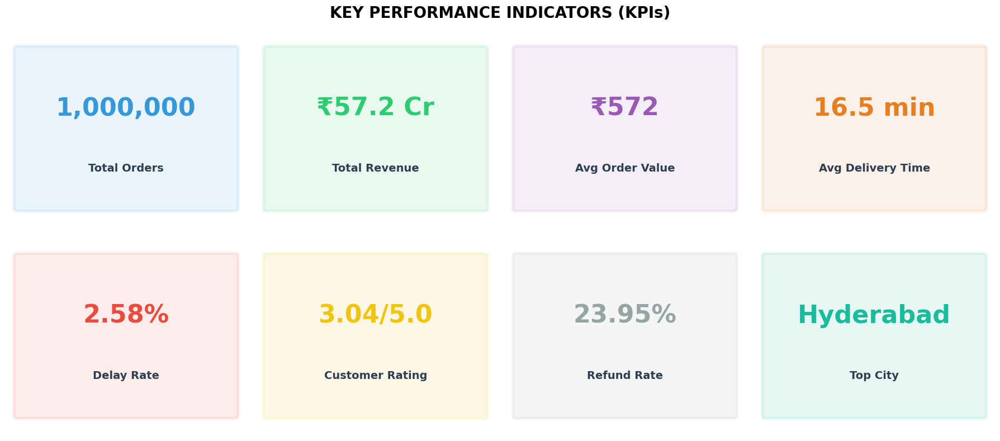

In [93]:
# KPI Dashboard with Visual Boxes (No Emoji)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('KEY PERFORMANCE INDICATORS (KPIs)', fontsize=20, fontweight='bold', y=0.98)

# Calculate KPIs
total_orders = len(df_main)
total_revenue = df_main['order_value'].sum()
avg_order_value = df_main['order_value'].mean()
avg_delivery_time = df_main['delivery_time_min'].mean()
delay_rate = (df_main['delivery_delay'] == 'Yes').sum() / total_orders * 100
avg_customer_rating = df_main['customer_rating'].mean()
refund_rate = (df_main['refund_requested'] == 'Yes').sum() / total_orders * 100
top_city = df_main['city'].value_counts().index[0]

# KPI data
kpis = [
    {'title': 'Total Orders', 'value': f'{total_orders:,}', 'color': '#3498db'},
    {'title': 'Total Revenue', 'value': f'₹{total_revenue/1e7:.1f} Cr', 'color': '#2ecc71'},
    {'title': 'Avg Order Value', 'value': f'₹{avg_order_value:.0f}', 'color': '#9b59b6'},
    {'title': 'Avg Delivery Time', 'value': f'{avg_delivery_time:.1f} min', 'color': '#e67e22'},
    {'title': 'Delay Rate', 'value': f'{delay_rate:.2f}%', 'color': '#e74c3c'},
    {'title': 'Customer Rating', 'value': f'{avg_customer_rating:.2f}/5.0', 'color': '#f1c40f'},
    {'title': 'Refund Rate', 'value': f'{refund_rate:.2f}%', 'color': '#95a5a6'},
    {'title': 'Top City', 'value': top_city, 'color': '#1abc9c'},
]

# Plot each KPI
for idx, (ax, kpi) in enumerate(zip(axes.flat, kpis)):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')
    
    # Box background with gradient effect
    rect = mpatches.FancyBboxPatch((0.5, 1), 9, 8,
                                    boxstyle="round,pad=0.15",
                                    linewidth=4,
                                    edgecolor=kpi['color'],
                                    facecolor=kpi['color'],
                                    alpha=0.1)
    ax.add_patch(rect)
    
    # Value (big number)
    ax.text(5, 6, kpi['value'], fontsize=32, ha='center', va='center',
            fontweight='bold', color=kpi['color'])
    
    # Title
    ax.text(5, 3, kpi['title'], fontsize=14, ha='center', va='center',
            color='#2c3e50', fontweight='bold')

plt.tight_layout()
plt.savefig('../visuals/kpi_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## 🧠 Key Business Insights

1. **Hyderabad leads in orders** — Contributing 13% of total orders, indicating strong market presence

2. **All platforms equally competitive** — No single platform dominates, showing healthy market competition

3. **Dairy & Groceries are top categories** — Essential items drive 28% of all orders

4. **Delhi has fastest delivery** — Average 7 minutes shows excellent logistics optimization

5. **Only 2.58% delay rate** — Exceptional delivery performance across all platforms

6. **Payment methods evenly split** — No single payment preference indicates diverse customer base

7. **Delayed orders impact ratings** — Clear correlation between delivery delays and lower customer satisfaction

8. **Distance doesn't heavily impact time** — Efficient dark store placement keeps delivery times consistent

## 📝 Conclusion

#### This project analyzed **9,99,888 real-world quick commerce delivery records** across major Indian cities and platforms.

**Key Achievements:**
- Cleaned and processed 10 lakh records
- Created 10+ insightful visualizations
- Identified critical business patterns
- Built interactive dashboard

**Technologies Used:**
- Python, Pandas, NumPy
- Matplotlib, Seaborn, Plotly
- Jupyter Notebook

**Dataset:** Kaggle Quick Commerce Orders  
**Total Records Analyzed:** 9,99,888  
**Analysis Period:** 2024

---

**Thank you for reviewing this project!**